In [28]:
!pip install -U transformers datasets accelerate scikit-learn


In [29]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.utils.class_weight import compute_class_weight

import random
import re

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    from transformers import set_seed as tf_set_seed
    tf_set_seed(seed)

set_seed(42)

from transformers import (
    BertTokenizerFast,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)


In [30]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/My Drive/Sora_LREC2020_biasedsentences.csv")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
raw_rows = []
# Step A: Clean individual sentences and align binary labels
for _, row in df.iterrows(): # Using 'df' as requested
    article_id = row["id_article"]
    for i in range(20):
        sentence = row[f"s{i}"]
        score = row[str(i)]
        if pd.notna(sentence) and pd.notna(score):
            # Remove artifacts like "[0]: " to clean the feature space
            clean_text = re.sub(r'^\[\d+\]:\s*', '', str(sentence)).strip()
            # 0 = Unbiased (score 0-1), 1 = Biased (score 2-4)
            label = 0 if int(score) <= 1 else 1
            raw_rows.append({"article_id": article_id, "sentence": clean_text, "label": label})

temp_df = pd.DataFrame(raw_rows)

# Step B: Label Consensus & Quality Filtering
refined_rows = []
# Grouping by article and sentence to handle annotator disagreement
grouped = temp_df.groupby(["article_id", "sentence"])

for (article_id, sentence), group in grouped:
    labels = group["label"].tolist()
    majority_label = max(set(labels), key=labels.count)
    agreement = labels.count(majority_label) / len(labels)

    # Excellent Level Filters:
    if len(labels) >= 1 and agreement >= 0.5:
        refined_rows.append({
            "article_id": article_id,
            "sentence": sentence,
            "label": majority_label
        })

sent_df = pd.DataFrame(refined_rows)
print(f"Refined dataset size: {len(sent_df)}")

Refined dataset size: 839


In [32]:
article_ids = sent_df["article_id"].unique()

train_ids, val_ids = train_test_split(
    article_ids,
    test_size=0.2,
    random_state=42
)

train_df = sent_df[sent_df["article_id"].isin(train_ids)]
val_df   = sent_df[sent_df["article_id"].isin(val_ids)]

print("Train sentences", len(train_df))
print("Validation sentences", len(val_df))


Train sentences 643
Validation sentences 196


In [33]:
train_ds = Dataset.from_pandas(train_df.reset_index(drop=True))
val_ds   = Dataset.from_pandas(val_df.reset_index(drop=True))


In [34]:
tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

def tokenize(batch):
    return tokenizer(
        batch["sentence"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])
val_ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])


Map:   0%|          | 0/643 [00:00<?, ? examples/s]

Map:   0%|          | 0/196 [00:00<?, ? examples/s]

In [35]:
train_labels = train_df["label"].values

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=train_labels
)

class_weights = torch.tensor(class_weights, dtype=torch.float)
class_weights


tensor([2.8964, 0.6043])

In [36]:
model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [37]:
def compute_metrics(pred):
    labels = pred.label_ids
    preds = np.argmax(pred.predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary"
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


In [38]:
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=8,
    weight_decay=0.01,
    logging_dir="./logs",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to=[]
)


In [39]:
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        loss_fct = nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )
        loss = loss_fct(logits, labels)

        return (loss, outputs) if return_outputs else loss

In [40]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)
trainer.train()


/tmp/ipython-input-3216068611.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `WeightedTrainer.__init__`. Use `processing_class` instead.
  trainer = WeightedTrainer(


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.647195,0.576531,0.903226,0.531646,0.669323
2,No log,0.657098,0.714286,0.880597,0.746835,0.808219
3,No log,0.794808,0.693878,0.850000,0.753165,0.798658
4,No log,1.062718,0.770408,0.842424,0.879747,0.860681
5,No log,1.237256,0.780612,0.844311,0.892405,0.867692
6,No log,1.564095,0.775510,0.831395,0.905063,0.866667
7,No log,1.643621,0.785714,0.841176,0.905063,0.871951
8,No log,1.698805,0.785714,0.841176,0.905063,0.871951


TrainOutput(global_step=328, training_loss=0.2488366103753811, metrics={'train_runtime': 233.7126, 'train_samples_per_second': 22.01, 'train_steps_per_second': 1.403, 'total_flos': 338360817192960.0, 'train_loss': 0.2488366103753811, 'epoch': 8.0})

In [41]:
results = trainer.evaluate()
results


{'eval_loss': 1.6436209678649902,
 'eval_accuracy': 0.7857142857142857,
 'eval_precision': 0.8411764705882353,
 'eval_recall': 0.9050632911392406,
 'eval_f1': 0.8719512195121951,
 'eval_runtime': 1.5532,
 'eval_samples_per_second': 126.191,
 'eval_steps_per_second': 8.37,
 'epoch': 8.0}

In [42]:
predictions = trainer.predict(val_ds)

y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Unbiased 0", "Biased 1"],
        digits=3
    )
)


              precision    recall  f1-score   support

  Unbiased 0      0.423     0.289     0.344        38
    Biased 1      0.841     0.905     0.872       158

    accuracy                          0.786       196
   macro avg      0.632     0.597     0.608       196
weighted avg      0.760     0.786     0.770       196



In [43]:
val_analysis_df = val_df.copy().reset_index(drop=True)

val_analysis_df["true_label"] = y_true
val_analysis_df["pred_label"] = y_pred
val_analysis_df["correct"] = val_analysis_df["true_label"] == val_analysis_df["pred_label"]


In [44]:
val_analysis_df.head()


,article_id,sentence,label,true_label,pred_label,correct
0,4.0,"""Back when the Constitution meant something, a...",0,0,1,False
1,4.0,"""The story was based on hearsay: no arrest, no...",1,1,1,True
2,4.0,After Kentucky State Rep. Dan Johnson died Wed...,1,1,1,True
3,4.0,"After the allegations broke, Kentucky lawmaker...",1,1,1,True
4,4.0,"At a press conference on Tuesday, Johnson deni...",1,1,1,True


In [45]:
misclassified_df = val_analysis_df[val_analysis_df["correct"] == False]

print("Total validation samples", len(val_analysis_df))
print("Misclassified ", len(misclassified_df))


Total validation samples 196
Misclassified  42


In [46]:
false_positives = misclassified_df[
    (misclassified_df["true_label"] == 0) &
    (misclassified_df["pred_label"] == 1)
]

false_negatives = misclassified_df[
    (misclassified_df["true_label"] == 1) &
    (misclassified_df["pred_label"] == 0)
]

print("False Positives (Unbiased - Biased):", len(false_positives))
print("False Negatives (Biased - Unbiased):", len(false_negatives))


False Positives (Unbiased - Biased): 27
False Negatives (Biased - Unbiased): 15


In [47]:
false_positives[["sentence"]].head(10)


,sentence
0,"""Back when the Constitution meant something, a..."
9,"Maranda Richmond, who did not respond to TIME'..."
11,"On Thursday afternoon, Johnson's widow said sh..."
14,"Paul Ham, the chairman of the Bullit County GO..."
21,But he was mostly out of the spotlight until t...
28,Johnson was elected to the State Legislature i...
31,The case has since been reopened.
34,The pastor of Heart of Fire church in Louisvil...
41,"""[O]nce again find ourselves in a position whe..."
50,"Mac Brown, chairman of the Republican Party of..."


In [48]:
false_negatives[["sentence"]].head(10)


,sentence
35,The post appears to have been removed.
59,"""I remember being super confused,"" said Mr. Wy..."
106,"He's fired.'"""
123,"""We're ready to talk anytime North Korea would..."
126,But can we at least sit down and see each othe...
145,"Let's just meet,"" Tillerson said at a forum in..."
146,The North has long expressed a willingness to ...
152,We are ready to have the first meeting without...
158,"""And the president is very realistic about tha..."
164,"""[W]e're ready to have the first meeting witho..."


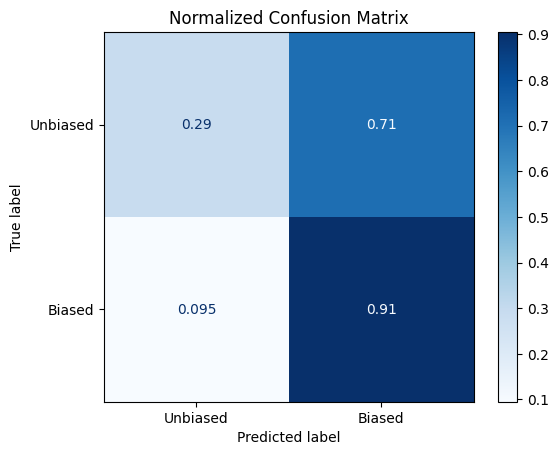

Worst performing articles:
article_id
42.0    0.450000
45.0    0.722222
5.0     0.750000
36.0    0.750000
26.0    0.800000
Name: correct, dtype: float64


In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get predictions
val_predictions = trainer.predict(val_ds)
y_true = val_predictions.label_ids
y_pred = np.argmax(val_predictions.predictions, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Unbiased", "Biased"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Normalized Confusion Matrix")
plt.show()

# Error analysis by article
val_df_with_pred = val_df.copy()
val_df_with_pred['prediction'] = y_pred
val_df_with_pred['correct'] = (val_df_with_pred['label'] == val_df_with_pred['prediction'])

# Accuracy by article
article_accuracy = val_df_with_pred.groupby('article_id')['correct'].mean()
print("Worst performing articles:")
print(article_accuracy.sort_values().head())

In [50]:
import pandas as pd
from IPython.display import display, HTML

# Create detailed error analysis
error_df = val_df.copy()
error_df['prediction'] = y_pred
error_df['confidence'] = np.max(torch.softmax(torch.tensor(val_predictions.predictions), dim=-1).numpy(), axis=1)
error_df['correct'] = error_df['label'] == error_df['prediction']

# Categorize errors
def categorize_error(row):
    if row['correct']:
        return 'Correct'
    elif row['label'] == 0 and row['prediction'] == 1:
        return 'False Positive (Unbiased to Biased)'
    else:
        return 'False Negative (Biased to Unbiased)'

error_df['error_type'] = error_df.apply(categorize_error, axis=1)

# Show statistics
error_stats = error_df['error_type'].value_counts()
print("Error Dist")
print(error_stats)
print("\naverage confidence by error type:")
print(error_df.groupby('error_type')['confidence'].mean())

# Interactive exploration
def explore_errors(error_type, n=5):
    samples = error_df[error_df['error_type'] == error_type].head(n)
    for idx, row in samples.iterrows():
        print(f"\nSentence: {row['sentence']}")
        print(f"True: {row['label']}, Pred: {row['prediction']}, Confidence: {row['confidence']:.3f}")

explore_errors('False Positive (Unbiased to Biased)', 5)

Error Dist
error_type
Correct                                154
False Positive (Unbiased to Biased)     27
False Negative (Biased to Unbiased)     15
Name: count, dtype: int64

average confidence by error type:
error_type
Correct                                0.964011
False Negative (Biased to Unbiased)    0.911086
False Positive (Unbiased to Biased)    0.951785
Name: confidence, dtype: float32

Sentence: "Back when the Constitution meant something, a man could stand before a jury of his peers.
True: 0, Pred: 1, Confidence: 0.904

Sentence: Maranda Richmond, who did not respond to TIME's request for comment on Thursday, told the news organization that Johnson molested her on New Year's Eve in 2012 when he was a pastor at the Heart of Fire Church.
True: 0, Pred: 1, Confidence: 0.996

Sentence: On Thursday afternoon, Johnson's widow said she wanted to take his seat in the Kentucky House.
True: 0, Pred: 1, Confidence: 0.996

Sentence: Paul Ham, the chairman of the Bullit County GOP, cri